# Breast Cancer Classification: LDA vs. QDA

**Course project:** Introduction to Mathematical Modelling, Department of Mathematics, Universitas Gadjah Mada (Group 7)

**Team:** Hening Arum Yudha, Manda Marwa Twandika, Moh Hasbi Alfarizi, Rafa Pavita Taputri, Yossaliano Andreas

This notebook classifies breast tumour cells as **malignant (1)** or **benign (0)** using
**Linear Discriminant Analysis (LDA)** and **Quadratic Discriminant Analysis (QDA)**, based on
8 cell-nucleus features from the Wisconsin Diagnostic Breast Cancer (WDBC) dataset.

> This is a cleaned-up, English version of the original Google Colab notebook. The modelling logic,
> features, split and random seed are unchanged, so the numbers match the original run. The only
> addition is the cross-validation section at the end, which was added later.

## 1. Imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn import metrics
from sklearn.datasets import load_breast_cancer
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis,
)
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split

FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 17
ALPHA = 0.05
CLASS_NAMES = ["Benign", "Malignant"]

## 2. Data

The original notebook read `Cancer_Data.csv` from
[Kaggle](https://www.kaggle.com/code/caouettem/cancer-classification-practice-97-accuracy/input). That file is the
[UCI WDBC dataset](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic)
(569 samples, 30 features), which also ships with scikit-learn. Here it is loaded from scikit-learn so
the notebook runs without downloading anything. The rows are in the same order, so the train/test split is identical.

Only the first 8 "mean" features are kept, as in the original project.

In [2]:
raw = load_breast_cancer(as_frame=True)

FEATURES = [
    "radius_mean", "texture_mean", "perimeter_mean", "area_mean",
    "smoothness_mean", "compactness_mean", "concavity_mean", "concave points_mean",
]

df = raw.data.iloc[:, :8].copy()
df.columns = FEATURES
# scikit-learn encodes malignant=0, benign=1; flip to Malignant=1, Benign=0 as in the original project
df.insert(0, "diagnosis", 1 - raw.target)
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   diagnosis            569 non-null    int64  
 1   radius_mean          569 non-null    float64
 2   texture_mean         569 non-null    float64
 3   perimeter_mean       569 non-null    float64
 4   area_mean            569 non-null    float64
 5   smoothness_mean      569 non-null    float64
 6   compactness_mean     569 non-null    float64
 7   concavity_mean       569 non-null    float64
 8   concave points_mean  569 non-null    float64
dtypes: float64(8), int64(1)
memory usage: 40.1 KB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
diagnosis,569.0,0.372583,0.483918,0.00000,0.00000,0.00000,1.0000,1.0000
radius_mean,569.0,14.127292,3.524049,6.98100,11.70000,13.37000,15.7800,28.1100
texture_mean,569.0,19.289649,4.301036,9.71000,16.17000,18.84000,21.8000,39.2800
perimeter_mean,569.0,91.969033,24.298981,43.79000,75.17000,86.24000,104.1000,188.5000
area_mean,569.0,654.889104,351.914129,143.50000,420.30000,551.10000,782.7000,2501.0000
smoothness_mean,569.0,0.096360,0.014064,0.05263,0.08637,0.09587,0.1053,0.1634
compactness_mean,569.0,0.104341,0.052813,0.01938,0.06492,0.09263,0.1304,0.3454
concavity_mean,569.0,0.088799,0.079720,0.00000,0.02956,0.06154,0.1307,0.4268
concave points_mean,569.0,0.048919,0.038803,0.00000,0.02031,0.03350,0.0740,0.2012


In [5]:
df["diagnosis"].value_counts().rename(index={0: "Benign (0)", 1: "Malignant (1)"})

diagnosis
Benign (0)       357
Malignant (1)    212
Name: count, dtype: int64

## 3. Exploratory data analysis

### 3.1 Feature distributions

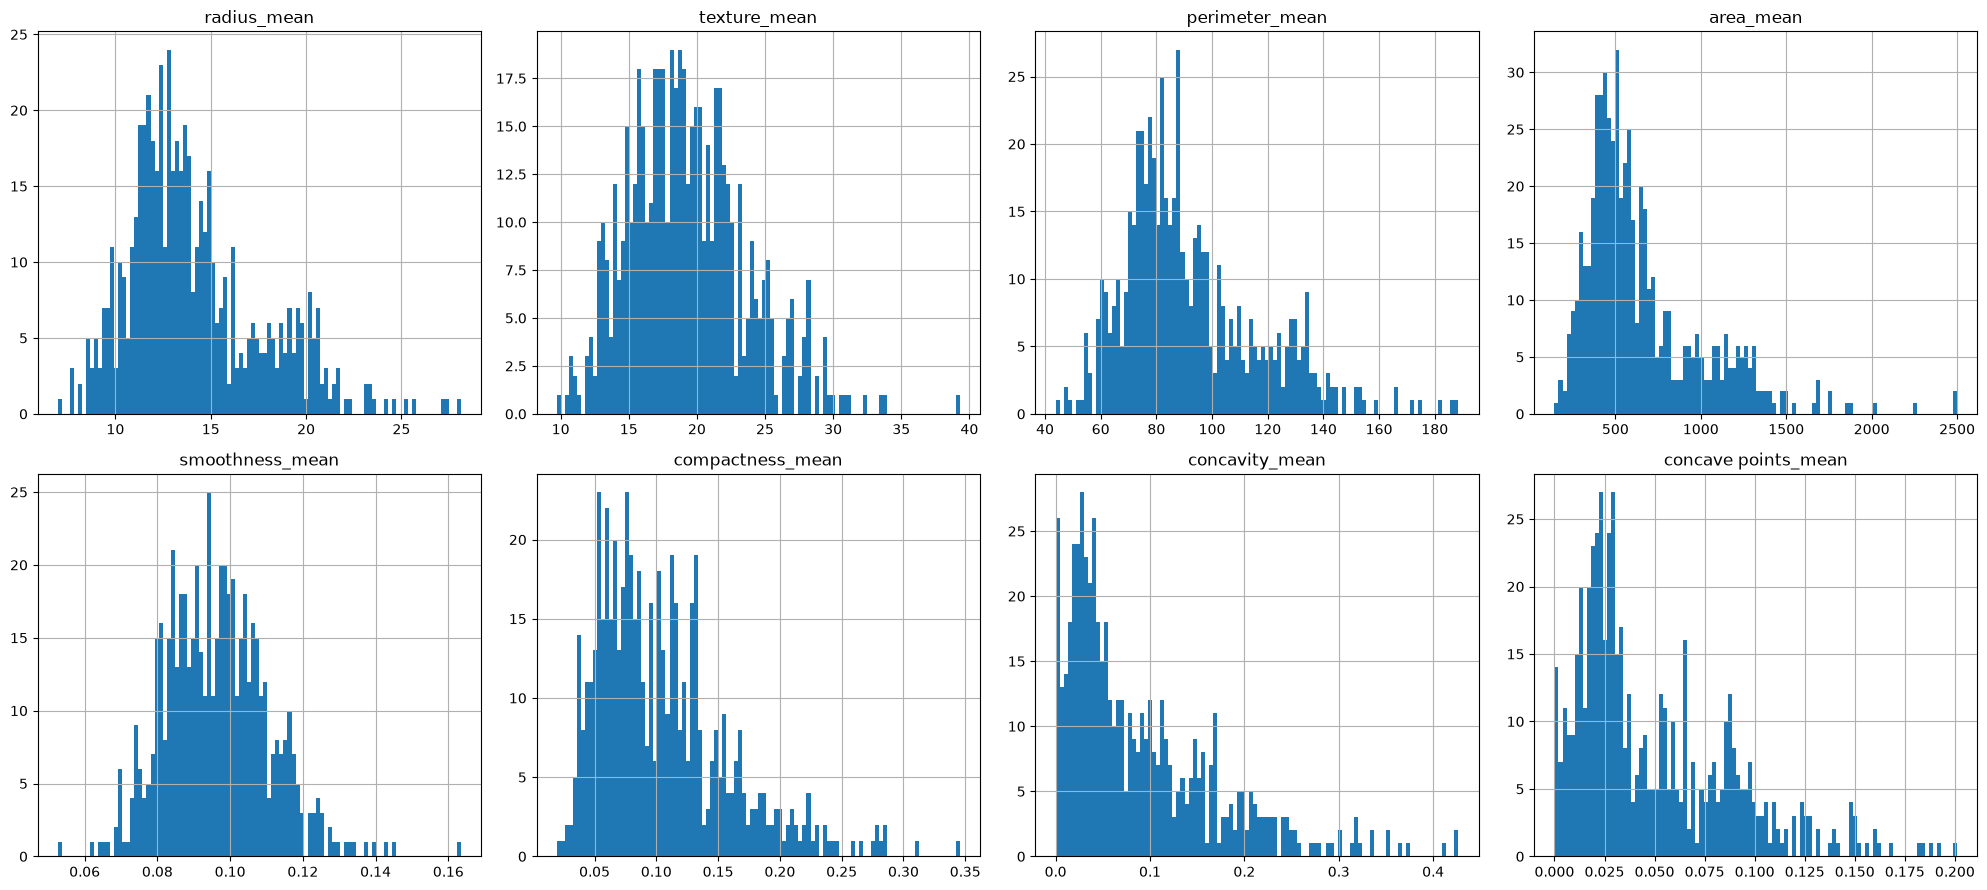

In [6]:
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 9))
for ax, col in zip(axes.flatten(), FEATURES):
    df[col].hist(bins=100, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig(FIG_DIR / "feature_distributions.png", dpi=120, bbox_inches="tight")
plt.show()

### 3.2 Normality test (D'Agostino–Pearson K²)

$H_0$: the feature is normally distributed. If every feature rejects $H_0$, a parametric
one-way ANOVA is not appropriate for feature screening, so a non-parametric test is used instead.

In [7]:
normality = []
for col in FEATURES:
    stat, p = stats.normaltest(df[col])
    normality.append({"feature": col, "K2 statistic": stat, "p-value": p, "normal (p > 0.05)": p > ALPHA})
normality = pd.DataFrame(normality).set_index("feature")
normality

,K2 statistic,p-value,normal (p > 0.05)
feature,,,
radius_mean,73.179382,1.286172e-16,False
texture_mean,42.962593,4.685883e-10,False
perimeter_mean,80.333718,3.595463e-18,False
area_mean,191.677877,2.386040e-42,False
smoothness_mean,28.365736,6.925619e-07,False
compactness_mean,113.118204,2.733343e-25,False
concavity_mean,141.507702,1.870652e-31,False
concave points_mean,101.085836,1.120701e-22,False


### 3.3 Kruskal–Wallis test (feature vs. diagnosis)

$H_0$: the feature has the same distribution in the benign and malignant groups. A rejected $H_0$
means the feature is related to the diagnosis.

In [8]:
kruskal = []
for col in FEATURES:
    groups = [df.loc[df["diagnosis"] == c, col] for c in (0, 1)]
    stat, p = stats.kruskal(*groups)
    kruskal.append({"feature": col, "H statistic": stat, "p-value": p, "significant (p < 0.05)": p < ALPHA})
kruskal = pd.DataFrame(kruskal).set_index("feature")
kruskal

,H statistic,p-value,significant (p < 0.05)
feature,,,
radius_mean,305.001142,2.680529e-68,True
texture_mean,121.220931,3.418606e-28,True
perimeter_mean,318.219885,3.537140e-71,True
area_mean,306.115524,1.532670e-68,True
smoothness_mean,78.556417,7.774588e-19,True
compactness_mean,210.859959,8.917618e-48,True
concavity_mean,305.436576,2.154564e-68,True
concave points_mean,343.693024,1.001402e-76,True


In [9]:
dropped = kruskal.index[~kruskal["significant (p < 0.05)"]].tolist()
print("Features not significantly related to diagnosis:", dropped or "none")

Features not significantly related to diagnosis: none


### 3.4 Correlation

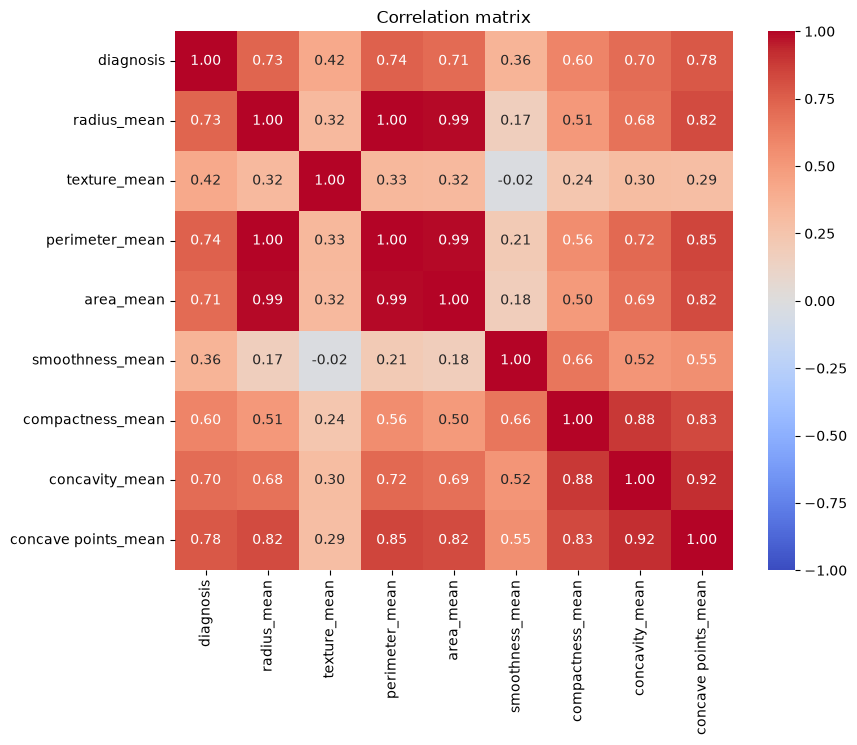

In [10]:
corr = df.corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.savefig(FIG_DIR / "correlation_heatmap.png", dpi=120, bbox_inches="tight")
plt.show()

In [11]:
corr["diagnosis"].drop("diagnosis").sort_values(ascending=False).to_frame("correlation with diagnosis")

,correlation with diagnosis
concave points_mean,0.776614
perimeter_mean,0.742636
radius_mean,0.730029
area_mean,0.708984
concavity_mean,0.696360
compactness_mean,0.596534
texture_mean,0.415185
smoothness_mean,0.358560


All 8 features pass the Kruskal–Wallis test and have a correlation with `diagnosis` above 0.1, so
all 8 are kept for modelling.

## 4. Train/test split

75% training, 25% testing, stratified by diagnosis, `random_state=17`.

In [12]:
X = df[FEATURES]
y = df["diagnosis"].values

train_X, test_X, train_y, test_y = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, shuffle=True, stratify=y
)
print(f"train: {train_X.shape}, test: {test_X.shape}")

train: (426, 8), test: (143, 8)


## 5. Models

In [13]:
def plot_confusion(y_true, y_pred, title, filename):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(title)
    plt.savefig(FIG_DIR / filename, dpi=120, bbox_inches="tight")
    plt.show()


def report(y_true, y_pred):
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES))

### 5.1 Linear Discriminant Analysis (LDA)

LDA models each class as a multivariate Gaussian with a **shared** covariance matrix $\Sigma$,
which gives a linear decision boundary:

$$\delta_k(x) = x^\top \Sigma^{-1}\mu_k - \tfrac{1}{2}\mu_k^\top \Sigma^{-1}\mu_k + \log \pi_k$$

In [14]:
lda = LinearDiscriminantAnalysis()
lda.fit(train_X, train_y)

lda_proba = lda.predict_proba(test_X)[:, 1]
lda_pred = lda.predict(test_X)  # default threshold 0.5
report(test_y, lda_pred)

Accuracy: 0.9371
              precision    recall  f1-score   support

      Benign       0.92      0.99      0.95        90
   Malignant       0.98      0.85      0.91        53

    accuracy                           0.94       143
   macro avg       0.95      0.92      0.93       143
weighted avg       0.94      0.94      0.94       143



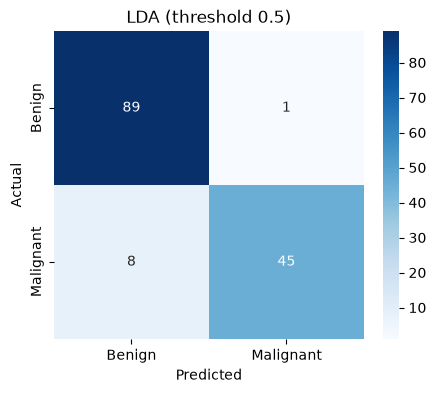

In [15]:
plot_confusion(test_y, lda_pred, "LDA (threshold 0.5)", "confusion_matrix_lda.png")

#### Lowering the decision threshold

In a screening setting a missed malignant tumour (false negative) is much worse than a false alarm.
Lowering the threshold from 0.5 to **0.265** (picked by looking at the ROC curve) trades a little
accuracy for higher sensitivity on the malignant class.

In [16]:
THRESHOLD = 0.265
lda_pred_tuned = (lda_proba >= THRESHOLD).astype(int)
report(test_y, lda_pred_tuned)

Accuracy: 0.9231
              precision    recall  f1-score   support

      Benign       0.94      0.93      0.94        90
   Malignant       0.89      0.91      0.90        53

    accuracy                           0.92       143
   macro avg       0.92      0.92      0.92       143
weighted avg       0.92      0.92      0.92       143



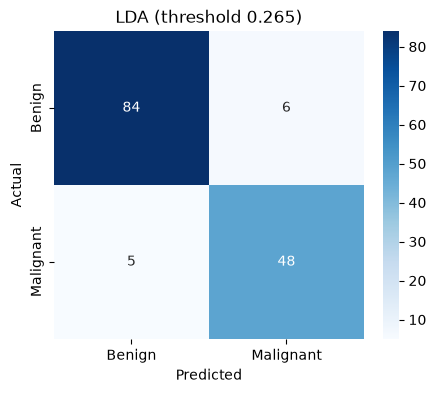

In [17]:
plot_confusion(test_y, lda_pred_tuned, f"LDA (threshold {THRESHOLD})", "confusion_matrix_lda_threshold.png")

### 5.2 Quadratic Discriminant Analysis (QDA)

QDA drops the shared-covariance assumption: each class gets its own $\Sigma_k$, giving a
quadratic decision boundary:

$$\delta_k(x) = -\tfrac{1}{2}\log|\Sigma_k| - \tfrac{1}{2}(x-\mu_k)^\top \Sigma_k^{-1}(x-\mu_k) + \log \pi_k$$

In [18]:
# radius, perimeter and area are almost perfectly collinear (perimeter ~ 2*pi*radius), so each class
# covariance is close to singular. Recent scikit-learn versions raise an error for this by default;
# a smaller `tol` restores the behaviour of the version used in the original project (same results).
qda = QuadraticDiscriminantAnalysis(tol=1e-12)
qda.fit(train_X, train_y)

qda_proba = qda.predict_proba(test_X)[:, 1]
qda_pred = qda.predict(test_X)
report(test_y, qda_pred)

Accuracy: 0.9091


              precision    recall  f1-score   support

      Benign       0.91      0.96      0.93        90
   Malignant       0.92      0.83      0.87        53

    accuracy                           0.91       143
   macro avg       0.91      0.89      0.90       143
weighted avg       0.91      0.91      0.91       143



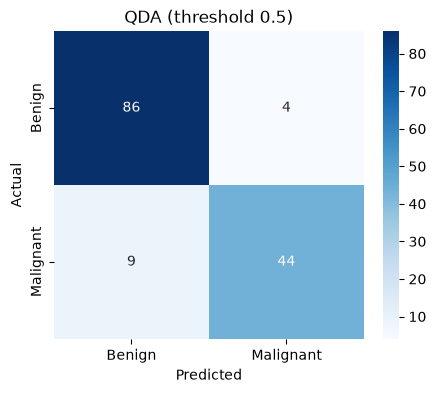

In [19]:
plot_confusion(test_y, qda_pred, "QDA (threshold 0.5)", "confusion_matrix_qda.png")

## 6. ROC curves and comparison

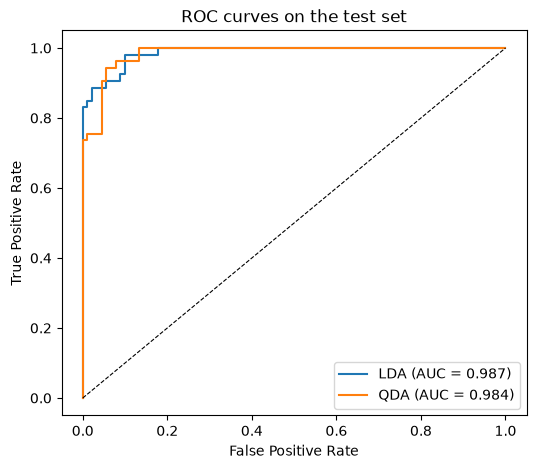

In [20]:
plt.figure(figsize=(6, 5))
for name, proba in [("LDA", lda_proba), ("QDA", qda_proba)]:
    fpr, tpr, _ = metrics.roc_curve(test_y, proba)
    auc = metrics.roc_auc_score(test_y, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=0.8)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curves on the test set")
plt.legend(loc="lower right")
plt.savefig(FIG_DIR / "roc_curves.png", dpi=120, bbox_inches="tight")
plt.show()

In [21]:
def summarize(name, y_true, y_pred, proba):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "sensitivity (malignant recall)": tp / (tp + fn),
        "specificity (benign recall)": tn / (tn + fp),
        "precision (malignant)": tp / (tp + fp),
        "ROC AUC": metrics.roc_auc_score(y_true, proba),
        "false negatives": fn,
    }

results = pd.DataFrame([
    summarize("LDA, threshold 0.5", test_y, lda_pred, lda_proba),
    summarize(f"LDA, threshold {THRESHOLD}", test_y, lda_pred_tuned, lda_proba),
    summarize("QDA, threshold 0.5", test_y, qda_pred, qda_proba),
]).set_index("model")
results.round(3)

,accuracy,sensitivity (malignant recall),specificity (benign recall),precision (malignant),ROC AUC,false negatives
model,,,,,,
"LDA, threshold 0.5",0.937,0.849,0.989,0.978,0.987,8
"LDA, threshold 0.265",0.923,0.906,0.933,0.889,0.987,5
"QDA, threshold 0.5",0.909,0.830,0.956,0.917,0.984,9


**Conclusion.** LDA beats QDA on accuracy, sensitivity and AUC. The project picked LDA with the
0.265 threshold as the final model, because it misses fewer malignant cases (5 instead of 8 false
negatives) for a small drop in overall accuracy.

## 7. Predictions on a held-out subset of the training data

The original project then split the training set again (75/25) and ran the final model on that subset.

In [22]:
_, val_X, _, val_y = train_test_split(
    train_X, train_y, test_size=0.25, random_state=RANDOM_STATE, shuffle=True, stratify=train_y
)
val_pred = (lda.predict_proba(val_X)[:, 1] >= THRESHOLD).astype(int)

n_malignant = int(val_pred.sum())
n_benign = len(val_pred) - n_malignant
print(f"{len(val_pred)} samples: {n_malignant} predicted malignant, {n_benign} predicted benign")

107 samples: 40 predicted malignant, 67 predicted benign


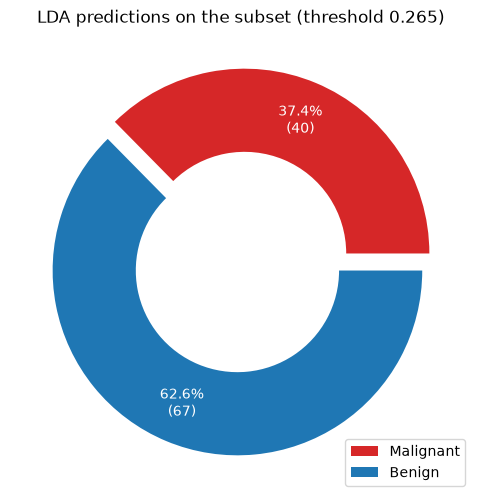

In [23]:
sizes = [n_malignant, n_benign]
plt.figure(figsize=(6, 6))
plt.pie(sizes, colors=["#d62728", "#1f77b4"],
        autopct=lambda p: f"{p:.1f}%\n({p * sum(sizes) / 100:.0f})",
        explode=(0.05, 0.05), pctdistance=0.78, textprops={"color": "w"},
        wedgeprops={"width": 0.45})
plt.legend(["Malignant", "Benign"], loc="lower right")
plt.title("LDA predictions on the subset (threshold 0.265)")
plt.savefig(FIG_DIR / "validation_predictions.png", dpi=120, bbox_inches="tight")
plt.show()

> **Note:** this subset comes from `train_X`, which the LDA model was already fitted on, so it is not
> truly unseen data. The test-set results in section 6 and the cross-validation below give a fairer
> estimate.

## 8. Addendum: stratified 5-fold cross-validation

*Added after the course.* A single 143-sample test set is small, and the 0.265 threshold was chosen
using that same test set. Cross-validation over the whole dataset gives a more stable comparison.

In [24]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "sensitivity": "recall", "roc_auc": "roc_auc"}

cv_rows = []
for name, model in [("LDA", LinearDiscriminantAnalysis()), ("QDA", QuadraticDiscriminantAnalysis(tol=1e-12))]:
    scores = cross_validate(model, X, y, cv=cv, scoring=scoring)
    row = {"model": name}
    for metric in scoring:
        s = scores[f"test_{metric}"]
        row[metric] = f"{s.mean():.3f} ± {s.std():.3f}"
    cv_rows.append(row)
pd.DataFrame(cv_rows).set_index("model")

,accuracy,sensitivity,roc_auc
model,,,
LDA,0.930 ± 0.026,0.858 ± 0.071,0.983 ± 0.011
QDA,0.919 ± 0.028,0.858 ± 0.059,0.981 ± 0.010
